In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import math
import os
import os.path
import time

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import plotnine as pn
import shapely
import scipy
import xarray as xr

from shoreshop3_analysis import util, data, wct, wavelet, transect_loaders, plot

In [3]:
ds = xr.open_zarr(data.global_coherence_path, consolidated=False)
ds

<xarray.Dataset> Size: 80MB
Dimensions:    (model: 43, transect: 970, scale: 120)
Coordinates:
  * model      (model) <U28 5kB 'BRIE' 'CCOST.DESM.recon' ... 'Traboulsi'
  * transect   (transect) <U9 35kB '0001_0001' '0001_0010' ... '0049_0229'
  * scale      (scale) int64 960B 0 1 2 3 4 5 6 ... 113 114 115 116 117 118 119
Data variables:
    period     (model, transect, scale) float64 40MB dask.array<chunksize=(1, 1, 120), meta=np.ndarray>
    coherence  (model, transect, scale) float64 40MB dask.array<chunksize=(1, 1, 120), meta=np.ndarray>
Attributes:
    title:    
    source:

In [5]:
ds.period[1, 0, :].values == ds.period[1, 0, :].values

array([ True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False])

In [7]:
coh = ds.coherence.values
coh

array([[[       nan,        nan,        nan, ...,        nan,
                nan,        nan],
        [       nan,        nan,        nan, ...,        nan,
                nan,        nan],
        [       nan,        nan,        nan, ...,        nan,
                nan,        nan],
        ...,
        [       nan,        nan,        nan, ...,        nan,
                nan,        nan],
        [       nan,        nan,        nan, ...,        nan,
                nan,        nan],
        [       nan,        nan,        nan, ...,        nan,
                nan,        nan]],

       [[0.41356626, 0.40589759, 0.38804877, ...,        nan,
                nan,        nan],
        [0.35334112, 0.29378225, 0.23993089, ...,        nan,
                nan,        nan],
        [0.26402677, 0.26123975, 0.27170289, ...,        nan,
                nan,        nan],
        ...,
        [0.26069601, 0.26454143, 0.28404485, ...,        nan,
                nan,        nan],
        [0.3

In [8]:
coh[coh < 0] = np.nan
coh[coh > 1] = np.nan

In [9]:
mean = coh.mean(axis=1)
mean

array([[       nan,        nan,        nan, ...,        nan,        nan,
               nan],
       [0.29922549, 0.2740422 , 0.25413489, ...,        nan,        nan,
               nan],
       [0.30254148, 0.27979161, 0.26014767, ...,        nan,        nan,
               nan],
       ...,
       [0.31474562, 0.29380706, 0.27595642, ...,        nan,        nan,
               nan],
       [0.40970711, 0.3965371 , 0.38630618, ...,        nan,        nan,
               nan],
       [       nan,        nan,        nan, ...,        nan,        nan,
               nan]], shape=(43, 120))

In [10]:
mean[1]

array([0.29922549, 0.2740422 , 0.25413489, 0.23747961, 0.22225199,
       0.20708387, 0.19378211, 0.18401336, 0.17888157, 0.17627017,
       0.17695019, 0.17950243, 0.18267654, 0.18433258, 0.18480643,
       0.18311952, 0.18137316, 0.18002146, 0.17956795, 0.1807399 ,
       0.1808712 , 0.18027192, 0.17888478, 0.17883264, 0.17899702,
       0.17850361, 0.17855981, 0.17984188, 0.18199587, 0.18289938,
       0.18314862, 0.18301505, 0.18224958, 0.18151534, 0.18119478,
       0.18173774, 0.18309289, 0.18445027, 0.18525329, 0.185692  ,
       0.1858563 , 0.18589382, 0.18498946, 0.1831363 , 0.18121691,
       0.18064368, 0.18252017, 0.18688406, 0.19270819, 0.19854981,
       0.20283709, 0.20514197, 0.20563836, 0.20464103, 0.20287844,
       0.20104635, 0.19888042, 0.19554328, 0.18980066, 0.18060947,
       0.1684134 , 0.15557092, 0.14576537, 0.14160165, 0.1417394 ,
       0.14201403, 0.14052936, 0.13722555, 0.13254435, 0.12763496,
       0.1227089 , 0.11765853, 0.11303038, 0.11032706, 0.11030

In [11]:
period_mask = ~np.isnan(mean).all(axis=0)
mean = mean[:, period_mask]

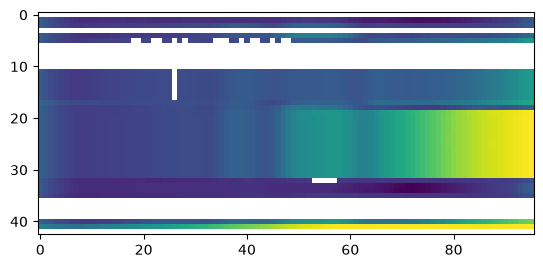

In [12]:
plt.imshow(mean, cmap='viridis')

In [13]:
np.min(mean[~np.isnan(mean)]), np.max(mean[~np.isnan(mean)])

(np.float64(0.08033247391165853), np.float64(0.834997470484668))

In [14]:
mean.shape

(43, 96)

In [15]:
mean_tosort = mean.copy()
mean_tosort[np.isnan(mean_tosort)] = 0
order = np.argsort(mean_tosort, axis=0)[::-1]
rank = np.argsort(order, axis=0)
rank

array([[42, 42, 42, ..., 42, 42, 42],
       [19, 19, 26, ..., 28, 28, 28],
       [17, 18, 18, ..., 25, 27, 27],
       ...,
       [ 2,  2,  2, ..., 14, 14, 14],
       [ 0,  0,  0, ...,  0,  0,  0],
       [31, 31, 31, ..., 31, 31, 31]], shape=(43, 96))

In [22]:
df = pd.DataFrame({
    'model': np.repeat(ds.model.values, mean.shape[1]),
    'period': np.tile(ds.period[1, 0, period_mask].values, mean.shape[0]),
    'coherence': mean.flatten(),
    'rank': rank.flatten(),
})

df

,model,period,coherence,rank
0,BRIE,16.000000,NaN,42
1,BRIE,16.951410,NaN,42
2,BRIE,17.959393,NaN,42
3,BRIE,19.027314,NaN,42
4,BRIE,20.158737,NaN,42
...,...,...,...,...
4123,Traboulsi,3068.532893,NaN,31
4124,Traboulsi,3250.997354,NaN,31
4125,Traboulsi,3444.311717,NaN,31
4126,Traboulsi,3649.121150,NaN,31


In [17]:
df[df['model'] == 'Mao.GraphShore']

,model,period,coherence,rank
3936,Mao.GraphShore,16.000000,0.409707,0
3937,Mao.GraphShore,16.951410,0.396537,0
3938,Mao.GraphShore,17.959393,0.386306,0
3939,Mao.GraphShore,19.027314,0.377817,0
3940,Mao.GraphShore,20.158737,0.370114,0
...,...,...,...,...
4027,Mao.GraphShore,3068.532893,0.828334,0
4028,Mao.GraphShore,3250.997354,0.829861,0
4029,Mao.GraphShore,3444.311717,0.831404,0
4030,Mao.GraphShore,3649.121150,0.833124,0


/hpc/home/sln33/shoreshop3-wavelets/venv/lib/python3.14/site-packages/plotnine/ggplot.py:623: PlotnineWarning: Saving 8 x 8 in image.
/hpc/home/sln33/shoreshop3-wavelets/venv/lib/python3.14/site-packages/plotnine/ggplot.py:624: PlotnineWarning: Filename: ../figures/mean-coherence.png


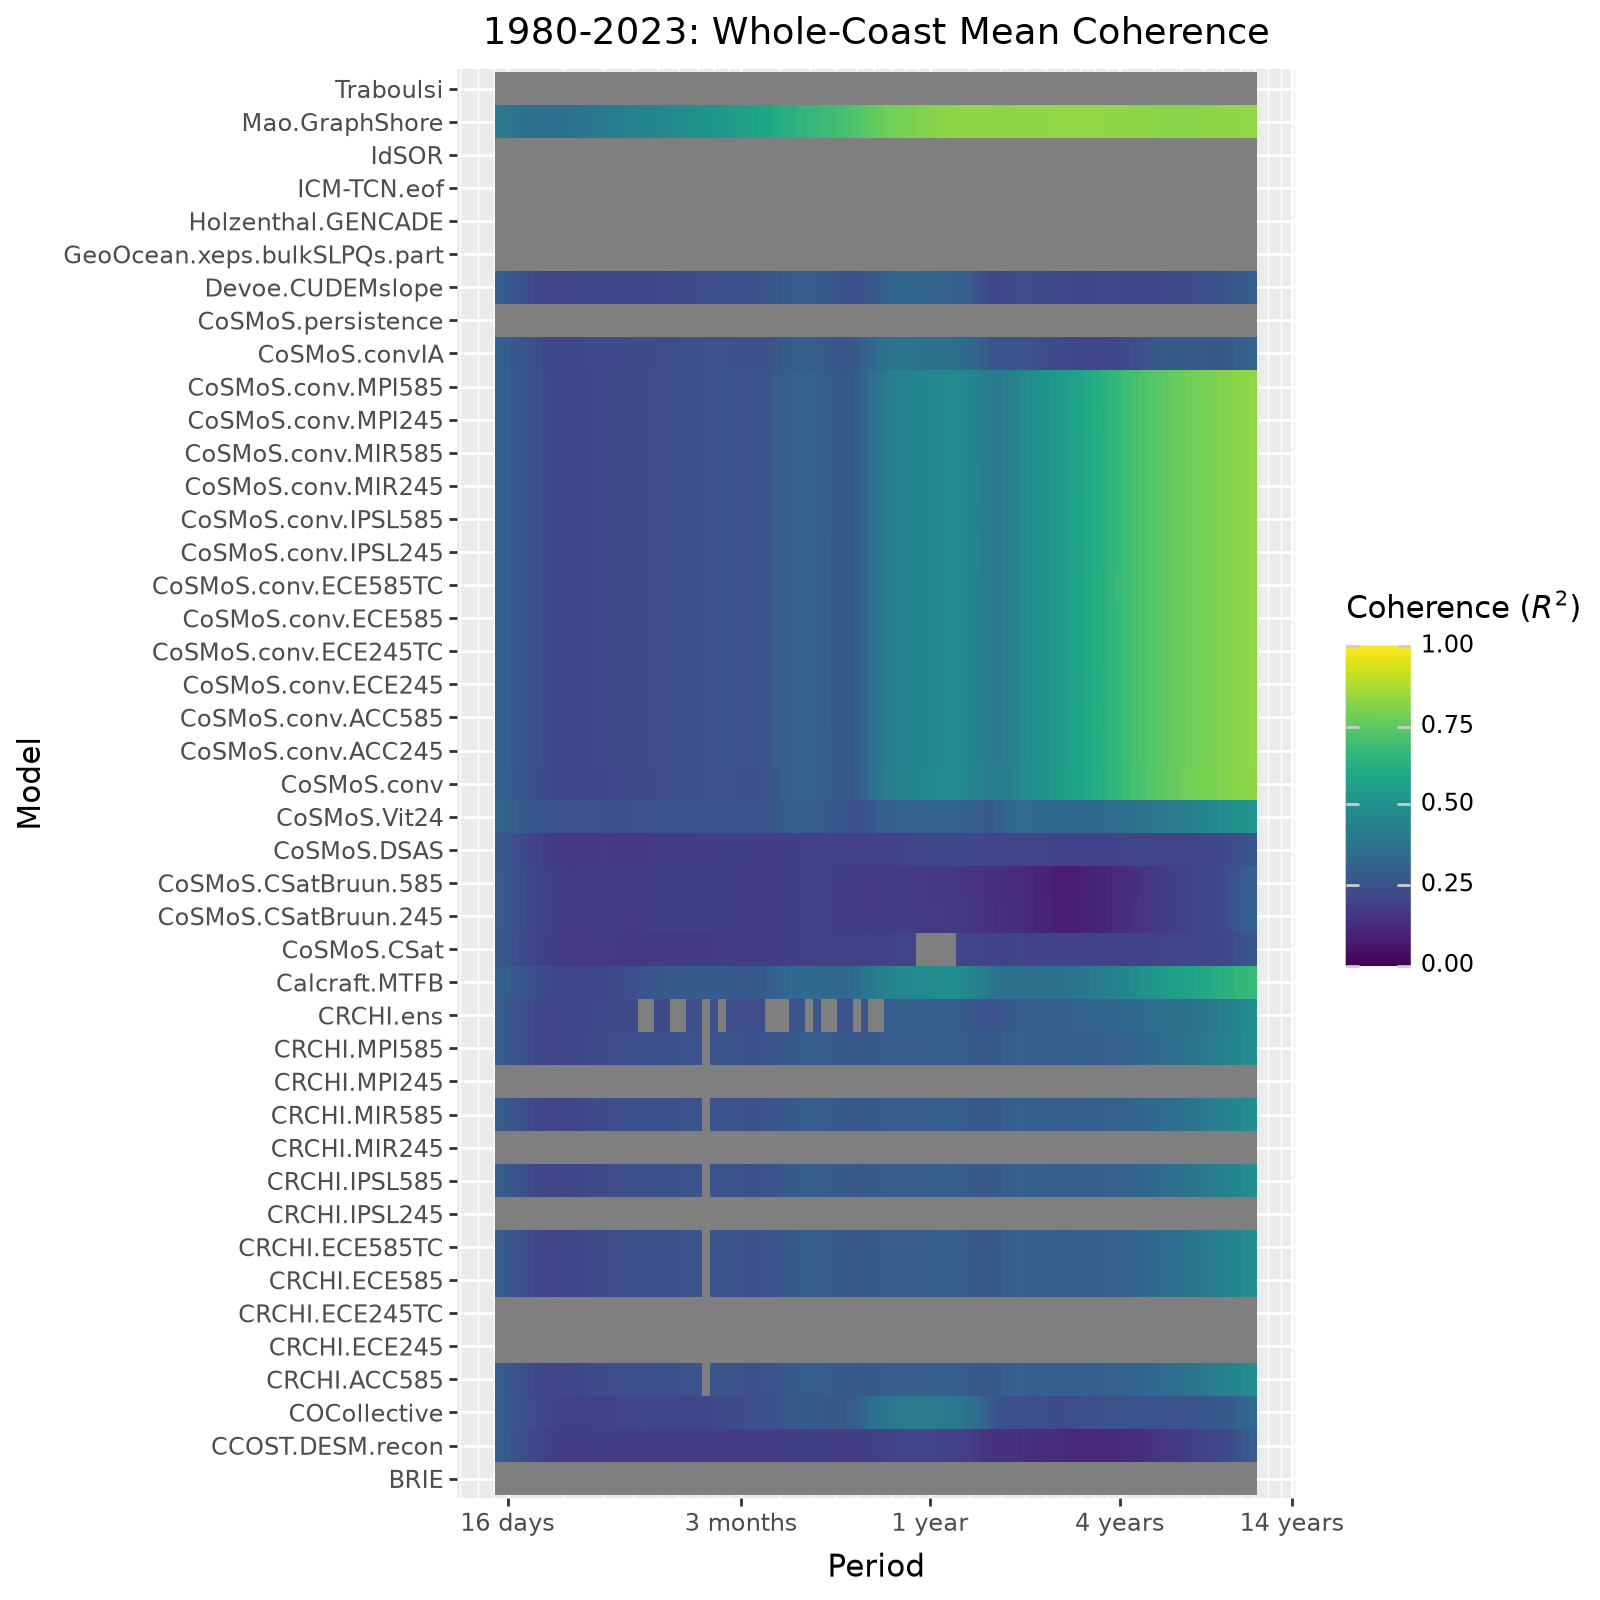

In [31]:
p = (
    pn.ggplot(df)
    + pn.geom_tile(pn.aes('period', 'model', fill='coherence'))
    + pn.scale_x_log10(
        breaks=[2, 17, 31*3, 367, 366*4, 366*14],
        labels=lambda breaks: list(map(wavelet.format_period, breaks)),
    )
    + pn.scale_fill_continuous(limits=(0, 1), cmap_name='viridis')
    + pn.labs(x='Period', y='Model', title='1980-2023: Whole-Coast Mean Coherence', fill='Coherence ($R^2$)')
    + pn.theme(figure_size=(8, 8))
)
p.save('../figures/mean-coherence.png', dpi=180)
p

In [25]:
df_nonan = df[~df['coherence'].isna().groupby(df['model']).transform('all')]
#df_nonan['rank'] = np.minimum(df_nonan['rank'].values, len(df_nonan['model'].unique()))
# df_nonan = df_nonan[df_nonan['period'].isin(df_nonan['period'].unique()[::2])]
mean_rank = df_nonan['rank'].groupby(df['model']).mean().argsort().argsort()
k = 10
topk = mean_rank[mean_rank < k]
print(topk.index.unique())
df_nonan = df_nonan[df_nonan['model'].isin(topk.index)]
df_nonan['rank'] = df_nonan.groupby('period')['coherence'].rank(method='first', ascending=False).astype(int) - 1
df_nonan

Index(['Calcraft.MTFB', 'CoSMoS.conv.ACC245', 'CoSMoS.conv.ACC585',
       'CoSMoS.conv.ECE245TC', 'CoSMoS.conv.ECE585', 'CoSMoS.conv.ECE585TC',
       'CoSMoS.conv.IPSL245', 'CoSMoS.conv.IPSL585', 'CoSMoS.conv.MIR585',
       'Mao.GraphShore'],
      dtype='str', name='model')


,model,period,coherence,rank
1920,CoSMoS.conv.ACC245,16.000000,0.311444,7
1921,CoSMoS.conv.ACC245,16.951410,0.290914,3
1922,CoSMoS.conv.ACC245,17.959393,0.273801,2
1923,CoSMoS.conv.ACC245,19.027314,0.259327,2
1924,CoSMoS.conv.ACC245,20.158737,0.246753,1
...,...,...,...,...
4027,Mao.GraphShore,3068.532893,0.828334,0
4028,Mao.GraphShore,3250.997354,0.829861,0
4029,Mao.GraphShore,3444.311717,0.831404,0
4030,Mao.GraphShore,3649.121150,0.833124,0


/hpc/home/sln33/shoreshop3-wavelets/venv/lib/python3.14/site-packages/plotnine/ggplot.py:623: PlotnineWarning: Saving 15 x 6 in image.
/hpc/home/sln33/shoreshop3-wavelets/venv/lib/python3.14/site-packages/plotnine/ggplot.py:624: PlotnineWarning: Filename: ../figures/topk-ranks.png


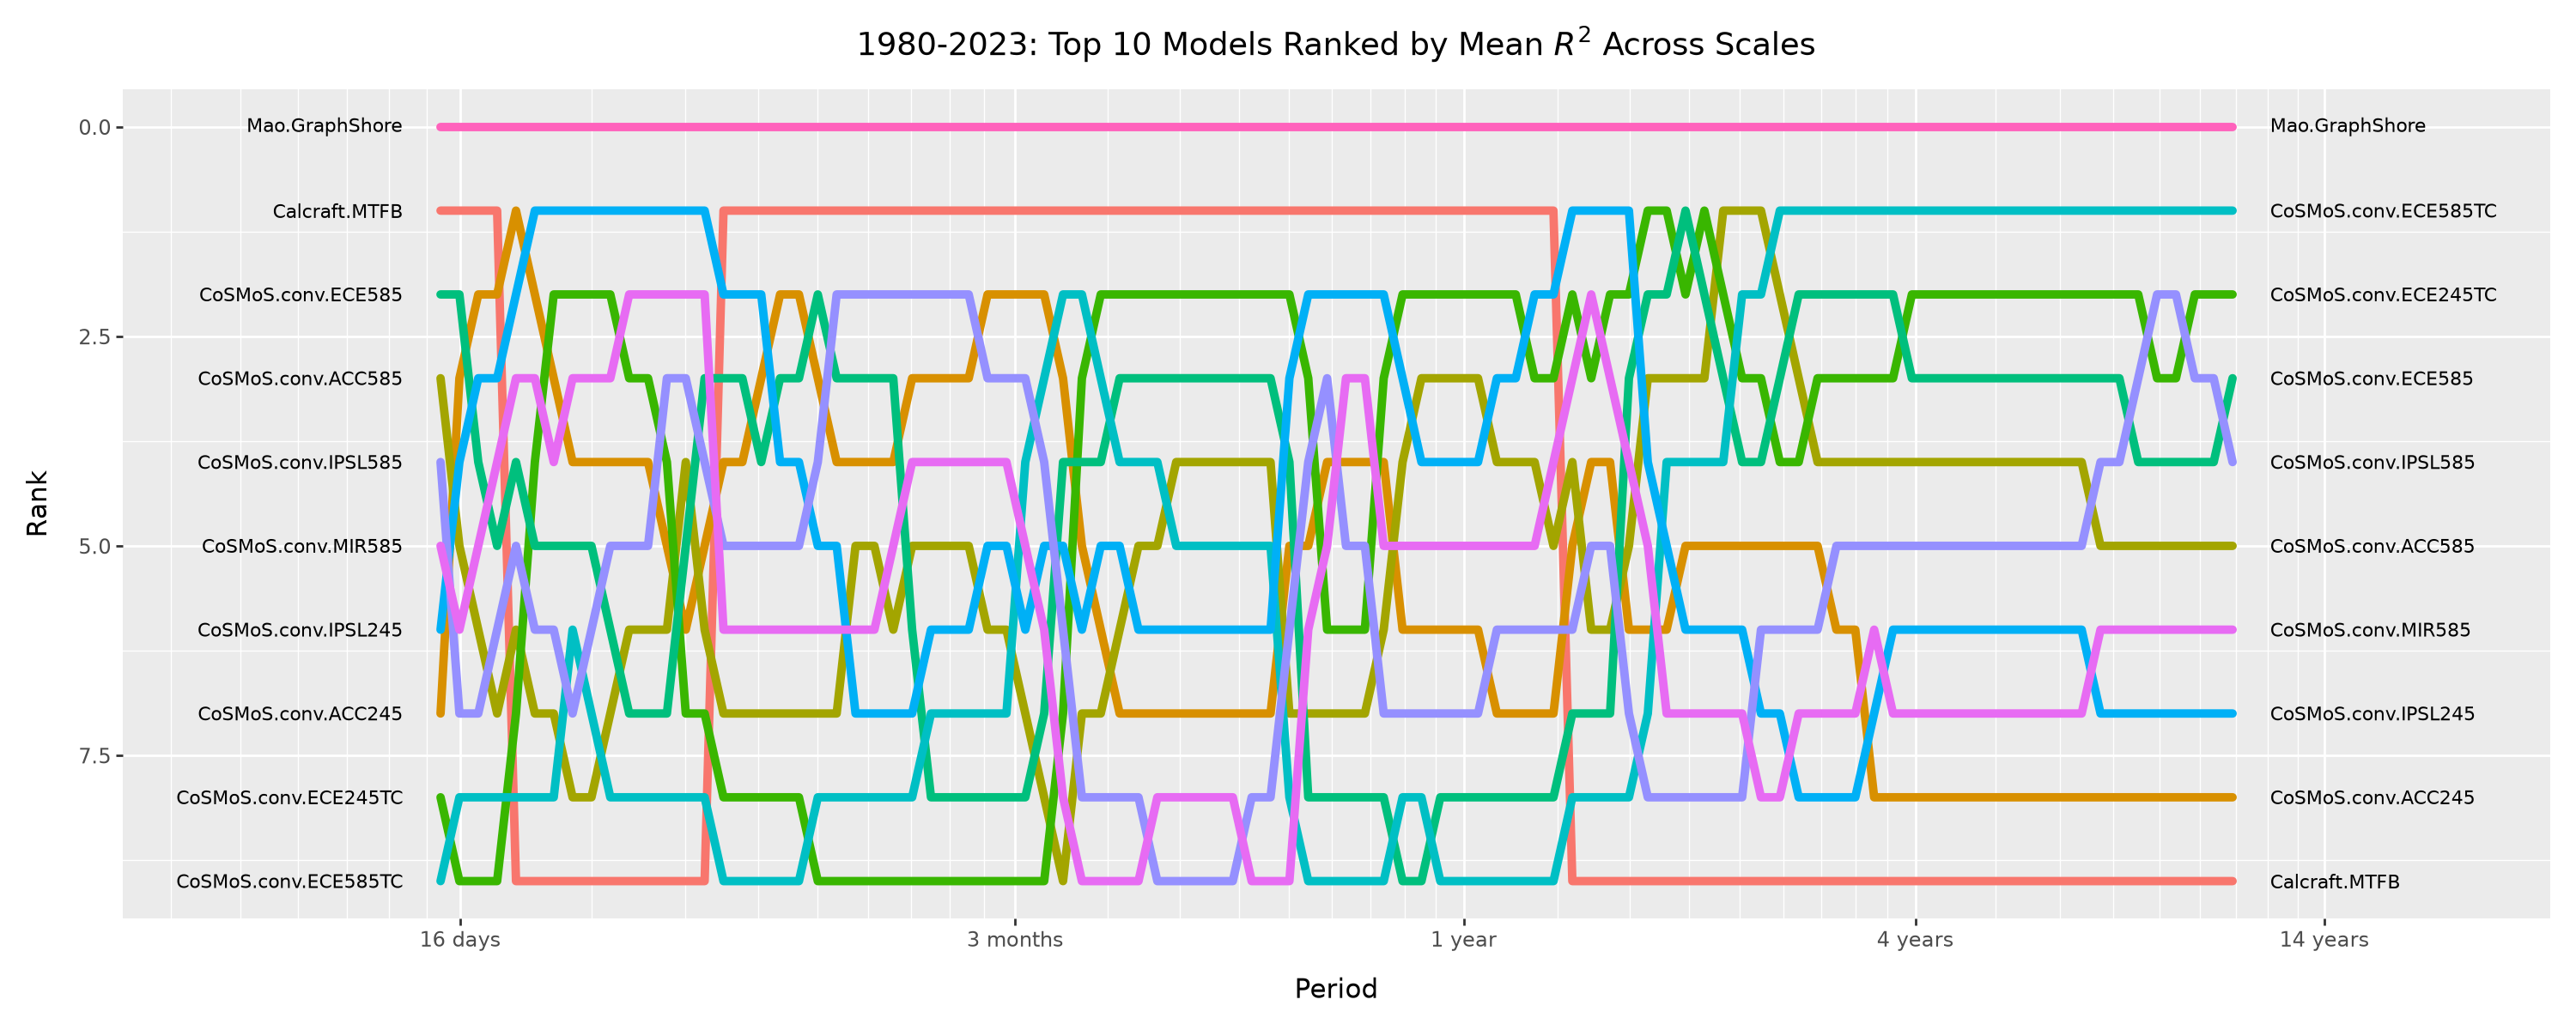

In [30]:
p = (
    pn.ggplot(df_nonan)
    + pn.geom_path(
        pn.aes('period', 'rank', group='model', color='model'),
        size=2,
        lineend='round',
    )
    + pn.geom_text(
        pn.aes('period', 'rank', label='model'),
        data=df_nonan[df_nonan['period'] == df_nonan['period'].min()],
        ha='right',
        size=8,
        nudge_x=-0.05,
    )
    + pn.geom_text(
        pn.aes('period', 'rank', label='model'),
        data=df_nonan[df_nonan['period'] == df_nonan['period'].max()],
        ha='left',
        size=8,
        nudge_x=0.05,
    )
    + pn.scale_x_log10(
        breaks=[2, 17, 31*3, 367, 366*4, 366*14],
        labels=lambda breaks: list(map(wavelet.format_period, breaks)),
        expand=(0.15, 0, 0.15, 0),
    )
    + pn.scale_y_reverse()
    #+ pn.scale_fill_hue()
    + pn.labs(x='Period', y='Rank', fill='Model', title=f'1980-2023: Top {k} Models Ranked by Mean $R^2$ Across Scales')
    + pn.theme(figure_size=(15, 6), legend_position='none')
)
p.save('../figures/topk-ranks.png')
p